# Acme Data Science Case: order completion time

Goal: predict `total_minutes`, the time a shopper needs to complete an order, and write a prediction for every
order without a label to `data/submission.csv`.

**Outline**
1. Build one row per order from the four tables (products → order size, shopper history, store and customer location, promised time).
2. EDA to check the features and the target.
3. Modelling with LightGBM. Every decision is checked with **5-fold shuffled cross-validation (mean ± std)** on the training part,
   and a 20% hold-out set is scored **only once**, at the end.
4. Error analysis, then a refit on **all** labeled orders to make the submission.

The model is evaluated with **MAE** (mean absolute error, in minutes), which is easy to read in business terms ("we're off by X minutes on average").

**How to run:** `python3.12 -m venv .venv && .venv/bin/pip install -r requirements-dev.txt`, then run this notebook top to bottom
(`.venv/bin/jupyter nbconvert --to notebook --execute --inplace case-ml.ipynb`).

The production pipeline in `src/` (training script, API, Docker image) re-implements the feature engineering and the final model from this notebook. See the README.

In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from lightgbm import LGBMRegressor
from scipy.stats import randint as sp_randint
from scipy.stats import uniform as sp_uniform
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_val_score, train_test_split

sns.set()
plt.rcParams['figure.dpi'] = 72          # keeps the committed notebook small
pd.set_option('display.max_columns', None)

RANDOM_STATE = 42
LOCAL_TZ = 'America/Santiago'           # all coordinates are in Chile

## Order Products

`order_products` has one row per (order, product). We collapse it to one row per order with three size features:
- `num_products`: number of distinct products (there are no duplicate (order, product) pairs, checked below),
- `un`: total units for products sold by unit,
- `kg`: total kilograms for products sold by weight.

In [2]:
order_products = pd.read_csv('./data/order_products.csv')
print(order_products.shape)
print('duplicate (order, product) rows:', order_products.duplicated(['order_id', 'product_id']).sum())
order_products.head()

(198500, 4)
duplicate (order, product) rows: 0


,order_id,product_id,quantity,buy_unit
0,47099653730fb1b76537fc10ad876255,c1244453d731c77416cb4766e3bd76cb,1.0,UN
1,689d8866915acf87e851c2591a23a82f,43cc2b100bec640fe563cd16f2db669f,1.0,KG
2,f26d16bf6f38c9e31d0be877f4013a9e,b8f880759d014134e272d881d49989a2,1.0,UN
3,161ccc896835ab41761b0e726becb6b1,dbc062b9bef805d27a6f4bea7edfe1f1,1.0,UN
4,4713deca10bb5db98fae150b52d61fc0,93a060f269bb569398921100f84c519a,2.0,UN


In [3]:
total_quantity = (order_products
                  .groupby(['order_id', 'buy_unit'])['quantity'].sum()
                  .unstack(fill_value=0)              # one column per unit; 0 if the order has none of that unit
                  .rename(columns={'KG': 'kg', 'UN': 'un'}))
total_quantity['num_products'] = order_products.groupby('order_id').size()
total_order_products = total_quantity.reset_index()
total_order_products.columns.name = None
print(total_order_products.shape)
total_order_products.head()

(9978, 4)


,order_id,kg,un,num_products
0,0004a3841c1eeb6c6e77585a941c21e0,0.000,8.0,4
1,0005a6ecbbde1e8d273f5577bcff2c9c,0.000,2.0,1
2,0007baeb6700fc203be2d1f1e11222d7,0.000,39.0,22
3,0012195a6a8ca9ec308a3010eeea8ebc,0.000,13.0,11
4,0013011fa72b498b9feb84f4e7104980,1.636,63.0,44


## Orders

In [4]:
orders = pd.read_csv('./data/orders.csv')
print(orders.shape)
orders.info()

(10000, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         10000 non-null  object 
 1   lat              10000 non-null  float64
 2   lng              10000 non-null  float64
 3   promised_time    10000 non-null  object 
 4   on_demand        10000 non-null  bool   
 5   shopper_id       10000 non-null  object 
 6   store_branch_id  10000 non-null  object 
 7   total_minutes    8000 non-null   float64
dtypes: bool(1), float64(3), object(4)
memory usage: 556.8+ KB


### Promised time: convert to local time

`promised_time` is stored in **UTC** (`+00:00`), but every order is in Chile, which was on UTC−3 in October 2019.
Hour-of-day and weekday features only mean something in local time: in UTC, about 1,300 Friday-evening orders look like
Saturday 00:00–03:00 orders. `tz_convert` handles daylight saving.

Features kept:
- `promised_weekday`, `promised_hour`, and their combination `promised_weekhour`.

Features **not** kept:
- *week of year*: every order is from the same week, so it carries no information.
- *minute*: 99.5% of scheduled orders are promised exactly on the hour, while on-demand orders get arbitrary minutes,
  so the minute mostly repeats `on_demand` and adds noise.

In [5]:
promised_utc = pd.to_datetime(orders['promised_time'])
promised_local = promised_utc.dt.tz_convert(LOCAL_TZ)

print('orders whose weekday changes after the conversion:', (promised_utc.dt.weekday != promised_local.dt.weekday).sum())
print('scheduled orders promised on the hour:', (promised_local[~orders['on_demand']].dt.minute == 0).mean().round(3))
print('on-demand orders promised on the hour:', (promised_local[orders['on_demand']].dt.minute == 0).mean().round(3))

orders['promised_weekday'] = promised_local.dt.weekday
orders['promised_hour'] = promised_local.dt.hour
orders['promised_weekhour'] = orders['promised_weekday'] * 24 + orders['promised_hour']
orders['on_demand'] = orders['on_demand'].astype(int)
orders = orders.drop(columns='promised_time')
orders.head()

orders whose weekday changes after the conversion: 1268
scheduled orders promised on the hour: 0.995
on-demand orders promised on the hour: 0.016


,order_id,lat,lng,on_demand,shopper_id,store_branch_id,total_minutes,promised_weekday,promised_hour,promised_weekhour
0,e750294655c2c7c34d83cc3181c09de4,-33.501675,-70.579369,1,e63bc83a1a952fa2b3cc9d558fb943cf,65ded5353c5ee48d0b7d48c591b8f430,67.684264,4,17,113
1,6581174846221cb6c467348e87f57641,-33.440584,-70.556283,0,195f9e9d84a4ba9033c4b6a756334d8b,45fbc6d3e05ebd93369ce542e8f2322d,57.060632,4,22,118
2,3a226ea48debc0a7ae9950d5540f2f34,-32.987022,-71.544842,1,a5b9ddc0d82e61582fca19ad43dbaacb,07563a3fe3bbe7e3ba84431ad9d055af,NaN,5,11,131
3,7d2ed03fe4966083e74b12694b1669d8,-33.328075,-70.512659,1,d0b3f6bf7e249e5ebb8d3129341773a2,f1748d6b0fd9d439f71450117eba2725,52.067742,4,18,114
4,b4b2682d77118155fe4716300ccf7f39,-33.403239,-70.564020,0,5c5199ce02f7b77caa9c2590a39ad27d,1f0e3dad99908345f7439f8ffabdffc4,140.724822,5,17,137


## Shoppers

In [6]:
shoppers = pd.read_csv('./data/shoppers.csv')
print(shoppers.shape)
shoppers.info()

(2864, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2864 entries, 0 to 2863
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   shopper_id     2864 non-null   object 
 1   seniority      2864 non-null   object 
 2   found_rate     2763 non-null   float64
 3   picking_speed  2864 non-null   float64
 4   accepted_rate  2837 non-null   float64
 5   rating         2780 non-null   float64
dtypes: float64(4), object(2)
memory usage: 134.4+ KB


`found_rate`, `accepted_rate` and `rating` have a few missing values. LightGBM handles NaNs natively, so we leave them as
they are. This also avoids any imputation statistics leaking from the test folds.

`seniority` is an anonymized hash with 4 levels. The order of the levels can't be recovered. Only one level stands out
(`6c90…` has about 40% lower picking speed, so it is probably the junior group) and the other three look the same.
Because of that, we encode it as an **unordered category** instead of inventing a 1–4 ranking.

In [7]:
shoppers.groupby('seniority')[['picking_speed', 'found_rate', 'accepted_rate', 'rating']].mean().round(3)

,picking_speed,found_rate,accepted_rate,rating
seniority,,,,
41dc7c9e385c4d2b6c1f7836973951bf,2.239,0.847,0.936,4.866
50e13ee63f086c2fe84229348bc91b5b,2.272,0.847,0.785,4.844
6c90661e6d2c7579f5ce337c3391dbb9,1.392,0.871,0.958,4.846
bb29b8d0d196b5db5a5350e5e3ae2b1f,2.274,0.856,0.783,4.861


In [8]:
shoppers['seniority'] = shoppers['seniority'].astype('category')

## Store branches

In [9]:
storebranch = pd.read_csv('./data/storebranch.csv')
print(storebranch.shape)
print('stores (chains):', storebranch['store_id'].nunique())
storebranch.head()

(476, 4)
stores (chains): 221


,store_branch_id,store_id,lat,lng
0,aff1621254f7c1be92f64550478c56e6,92cc227532d17e56e07902b254dfad10,-33.422497,-70.609231
1,56352739f59643540a3a6e16985f62c7,0336dcbab05b9d5ad24f4333c7658a0e,-33.385484,-70.555579
2,7d04bbbe5494ae9d2f5a76aa1c00fa2f,9bf31c7ff062936a96d3c8bd1f8f2ff3,-33.416579,-70.565224
3,2b24d495052a8ce66358eb576b8912c8,c4ca4238a0b923820dcc509a6f75849b,-33.512578,-70.655952
4,5487315b1286f907165907aa8fc96619,d82c8d1619ad8176d665453cfb2e55f0,-33.347645,-70.542229


Each branch belongs to one of 221 stores (chains). The store affects how long picking takes (store layout, typical
basket, queues), so `store_id` is kept as a **categorical** feature.

In [10]:
storebranch['store_id'] = storebranch['store_id'].astype('category')

## Merging the datasets

All merges are **left joins on `orders`**, so we never lose an order. 22 orders have no rows in `order_products`,
and 5 of them have no label, so they still need a prediction. With an inner join they would disappear from the
submission without any error. We keep them with NaN size features, which LightGBM can route to their own branch of each tree.
The asserts guard against this kind of silent row loss.

In [11]:
df = (orders
      .merge(total_order_products, on='order_id', how='left')
      .merge(shoppers, on='shopper_id', how='left')
      .merge(storebranch, on='store_branch_id', how='left', suffixes=('', '_store')))

assert len(df) == len(orders) and df['order_id'].is_unique
assert df['seniority'].notna().all() and df['store_id'].notna().all()   # every shopper / branch was found

no_products = df['num_products'].isna()
print('orders without products:', no_products.sum(), '| of which unlabeled:', (no_products & df['total_minutes'].isna()).sum())
df.shape

orders without products: 22 | of which unlabeled: 5


(10000, 21)

## Location features

The haversine formula approximates the straight-line distance (km) between store and customer. We also **keep the
raw coordinates** of both store and customer. Orders range from latitude −29.8 to −36.9, so they cover several cities
with different traffic, and the trees can use the coordinates to learn regional effects.

In [12]:
def haversine(lat1, lng1, lat2, lng2):
    """Great-circle distance in km between two (lat, lng) points given in degrees."""
    lat1, lng1, lat2, lng2 = map(np.radians, (lat1, lng1, lat2, lng2))
    earth_radius_in_km = 6371
    d = np.sin((lat2 - lat1) * 0.5) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) * 0.5) ** 2
    return 2 * earth_radius_in_km * np.arcsin(np.sqrt(d))

df['distance_haversine'] = haversine(df['lat'], df['lng'], df['lat_store'], df['lng_store'])
# shopper_id / store_branch_id are kept (but not used as features) for the grouped-CV check later on.
df.head()

,order_id,lat,lng,on_demand,shopper_id,store_branch_id,total_minutes,promised_weekday,promised_hour,promised_weekhour,kg,un,num_products,seniority,found_rate,picking_speed,accepted_rate,rating,store_id,lat_store,lng_store,distance_haversine
0,e750294655c2c7c34d83cc3181c09de4,-33.501675,-70.579369,1,e63bc83a1a952fa2b3cc9d558fb943cf,65ded5353c5ee48d0b7d48c591b8f430,67.684264,4,17,113,2.756,16.0,19.0,6c90661e6d2c7579f5ce337c3391dbb9,0.9024,1.30,0.92,4.76,c4ca4238a0b923820dcc509a6f75849b,-33.485280,-70.579250,1.823025
1,6581174846221cb6c467348e87f57641,-33.440584,-70.556283,0,195f9e9d84a4ba9033c4b6a756334d8b,45fbc6d3e05ebd93369ce542e8f2322d,57.060632,4,22,118,0.000,11.0,5.0,41dc7c9e385c4d2b6c1f7836973951bf,0.7610,2.54,0.92,4.96,c4ca4238a0b923820dcc509a6f75849b,-33.441246,-70.535450,1.934418
2,3a226ea48debc0a7ae9950d5540f2f34,-32.987022,-71.544842,1,a5b9ddc0d82e61582fca19ad43dbaacb,07563a3fe3bbe7e3ba84431ad9d055af,NaN,5,11,131,0.000,18.0,5.0,50e13ee63f086c2fe84229348bc91b5b,0.8313,2.57,0.76,4.92,c4ca4238a0b923820dcc509a6f75849b,-33.008213,-71.545615,2.357388
3,7d2ed03fe4966083e74b12694b1669d8,-33.328075,-70.512659,1,d0b3f6bf7e249e5ebb8d3129341773a2,f1748d6b0fd9d439f71450117eba2725,52.067742,4,18,114,0.000,1.0,1.0,41dc7c9e385c4d2b6c1f7836973951bf,0.8776,2.80,0.96,4.76,f718499c1c8cef6730f9fd03c8125cab,-33.355258,-70.537787,3.819046
4,b4b2682d77118155fe4716300ccf7f39,-33.403239,-70.564020,0,5c5199ce02f7b77caa9c2590a39ad27d,1f0e3dad99908345f7439f8ffabdffc4,140.724822,5,17,137,6.721,91.0,51.0,50e13ee63f086c2fe84229348bc91b5b,0.7838,2.40,0.96,4.96,c4ca4238a0b923820dcc509a6f75849b,-33.386547,-70.568075,1.893879


## EDA

### Target

count    8000.0
mean       81.1
std        34.7
min        12.0
25%        55.2
50%        74.7
75%       100.3
max       304.2
Name: total_minutes, dtype: float64
skew: 1.03


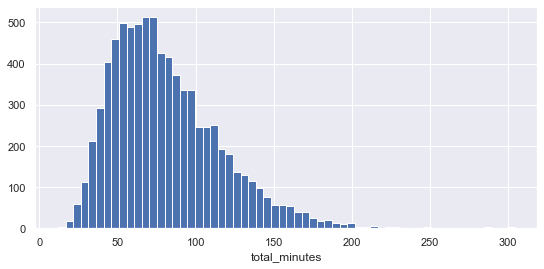

In [13]:
labeled = df[df['total_minutes'].notna()]
print(labeled['total_minutes'].describe().round(1))
print('skew:', round(labeled['total_minutes'].skew(), 2))
labeled['total_minutes'].hist(bins=60, figsize=(9, 4))
plt.xlabel('total_minutes'); plt.show()

The target is right-skewed (median 75 min, max 304 min). Since we are measured on MAE, we train with the **L1 objective**,
which estimates the conditional median and is robust to the long tail. We also tried a log-transformed target, and its
CV MAE was no better (see the README).

### Feature distributions and correlations

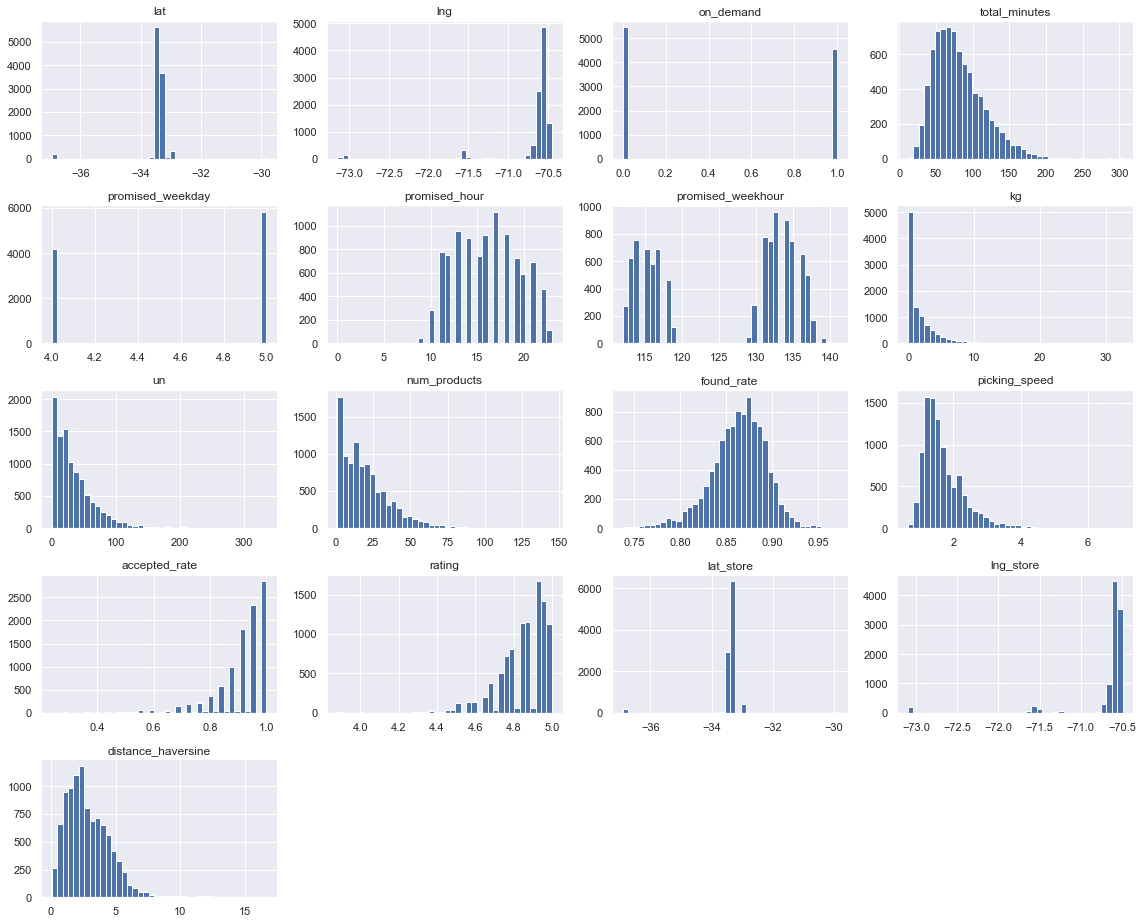

In [14]:
df.hist(figsize=(16, 13), bins=40)
plt.tight_layout(); plt.show()

Most size features are heavy-tailed. Once converted to local time, orders cover Friday and Saturday from about 09:00 to 23:00.

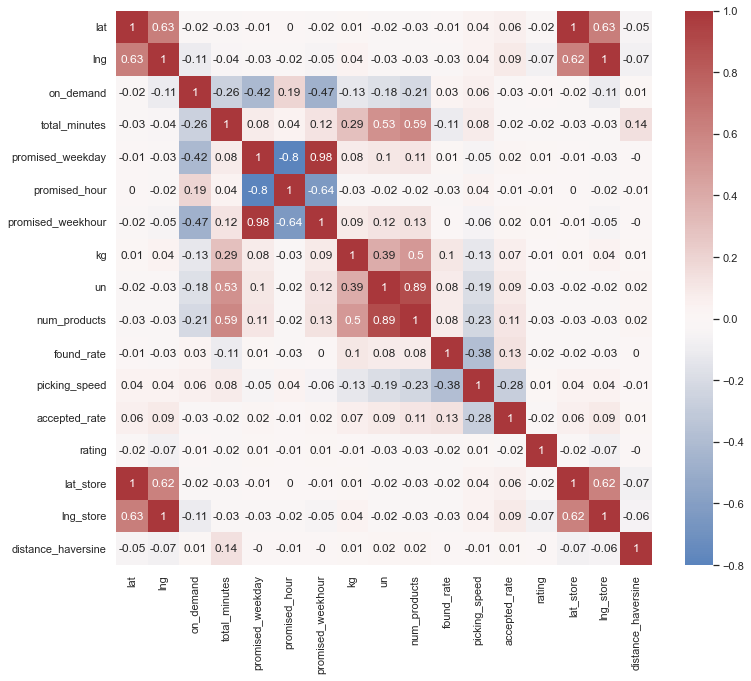

In [15]:
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(df.corr(numeric_only=True).round(2), annot=True, ax=ax, cmap='vlag', center=0)
plt.show()

As expected, `total_minutes` correlates most with order size (`num_products`, `un`, then `kg`). Surprisingly,
`picking_speed` is *not* negatively correlated with the target (≈ +0.08), because it is confounded with order size:
slower shoppers tend to get smaller orders (correlation ≈ −0.23 with `num_products`). This is why we use a model that
can learn interactions instead of reading features one at a time.

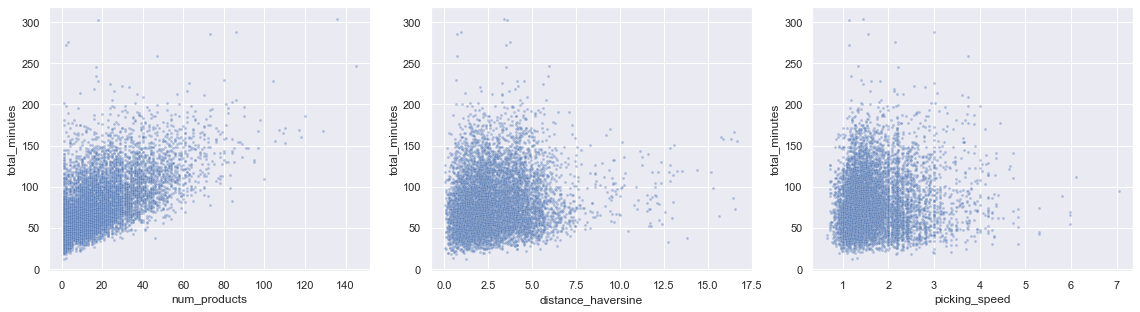

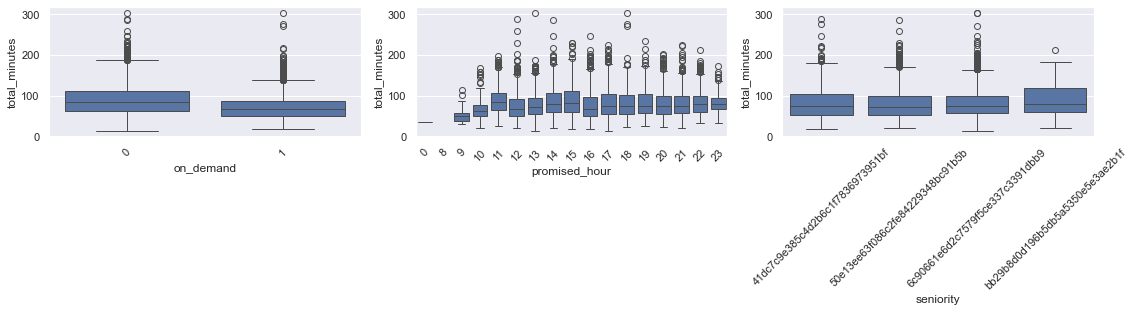

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ['num_products', 'distance_haversine', 'picking_speed']):
    sns.scatterplot(x=col, y='total_minutes', data=df, s=8, alpha=0.4, ax=ax)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ['on_demand', 'promised_hour', 'seniority']):
    sns.boxplot(x=col, y='total_minutes', data=df, ax=ax)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

- `num_products` has a strong, roughly linear relationship with the target, with spread that grows as orders get bigger.
- On-demand orders are faster (≈ 71 vs 89 min on average), largely because they are smaller (≈ 16 vs 23 products).
- Total time hardly differs across seniority levels, even for the slow-picking level, because of the same order-size confounding.

## Modeling

### Data split
- Rows **without** `total_minutes` are set aside for the submission.
- The labeled rows are split 80/20. The 20% **hold-out set is used only once**, for the final estimate. Every model
  and feature decision is made with 5-fold *shuffled* CV on the 80%.

In [17]:
FEATURES = ['num_products', 'kg', 'un', 'on_demand',
            'promised_weekday', 'promised_hour', 'promised_weekhour',
            'seniority', 'found_rate', 'picking_speed', 'accepted_rate', 'rating',
            'store_id', 'distance_haversine', 'lat', 'lng', 'lat_store', 'lng_store']

submission_df = df[df['total_minutes'].isna()]
labeled = df[df['total_minutes'].notna()]
print('labeled:', len(labeled), '| to predict:', len(submission_df))

X, y = labeled[FEATURES], labeled['total_minutes']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_mae(model, features=FEATURES):
    """5-fold CV MAE on the training split, returned as (mean, std)."""
    scores = -cross_val_score(model, X_train[features], y_train, cv=cv, scoring='neg_mean_absolute_error')
    return scores.mean(), scores.std()

def lgbm(**params):
    return LGBMRegressor(random_state=RANDOM_STATE, verbose=-1, **params)

labeled: 8000 | to predict: 2000


### Baseline
A model that always predicts the training mean. A useful model has to beat it by a wide margin.

In [18]:
print('Mean baseline CV MAE: {:.2f} ± {:.2f}'.format(*cv_mae(DummyRegressor(strategy='mean'))))
print('Median baseline CV MAE: {:.2f} ± {:.2f}'.format(*cv_mae(DummyRegressor(strategy='median'))))

Mean baseline CV MAE: 27.28 ± 0.70
Median baseline CV MAE: 26.77 ± 0.62


### Feature / objective ablation
Each step adds one change, so we can see what it's worth. The fold-to-fold std is about 0.3 min, so differences
smaller than that are noise.

In [19]:
size = ['num_products', 'kg', 'un', 'on_demand']
time = ['promised_weekday', 'promised_hour', 'promised_weekhour']
shopper = ['seniority', 'found_rate', 'picking_speed', 'accepted_rate', 'rating']
steps = [
    ('size + time + shopper + distance, L2 loss', size + time + shopper + ['distance_haversine'], {}),
    ('  + L1 loss (matches the MAE metric)',      size + time + shopper + ['distance_haversine'], {'objective': 'l1'}),
    ('  + store_id (categorical)',                size + time + shopper + ['distance_haversine', 'store_id'], {'objective': 'l1'}),
    ('  + store & customer coordinates',          FEATURES, {'objective': 'l1'}),
]
ablation = pd.DataFrame(
    [(name, *cv_mae(lgbm(**params), feats)) for name, feats, params in steps],
    columns=['step', 'cv_mae', 'cv_std']).round(2)
ablation

,step,cv_mae,cv_std
0,"size + time + shopper + distance, L2 loss",18.58,0.45
1,+ L1 loss (matches the MAE metric),18.34,0.51
2,+ store_id (categorical),18.10,0.46
3,+ store & customer coordinates,16.42,0.49


Every step helps. Matching the loss to the metric and adding location information (store chain and coordinates) give the largest gains.

### Hyperparameter search
Notes on the search:
- `subsample` only has an effect in LightGBM when `subsample_freq > 0`, so we set `subsample_freq=1`.
- The learning rate and number of trees are searched together.
- No `eval_set` is passed: the hold-out set must not be touched during model selection.
- We compare the best result with the default parameters and keep the tuned model **only if it is clearly better**.

In [20]:
param_distributions = {
    'n_estimators': sp_randint(100, 1000),
    'learning_rate': [0.01, 0.02, 0.03, 0.05, 0.1],
    'num_leaves': sp_randint(8, 64),
    'min_child_samples': sp_randint(10, 200),
    'subsample': sp_uniform(loc=0.5, scale=0.5),
    'colsample_bytree': sp_uniform(loc=0.4, scale=0.6),
    'reg_alpha': [0, 0.1, 1, 5, 10],
    'reg_lambda': [0, 0.1, 1, 5, 10, 50],
}
search = RandomizedSearchCV(
    estimator=lgbm(objective='l1', subsample_freq=1),
    param_distributions=param_distributions,
    n_iter=50, scoring='neg_mean_absolute_error', cv=cv,
    random_state=RANDOM_STATE, n_jobs=-1, refit=False)
search.fit(X_train, y_train)

best = search.best_index_
tuned_mean = -search.cv_results_['mean_test_score'][best]
tuned_std = search.cv_results_['std_test_score'][best]
default_mean, default_std = cv_mae(lgbm(objective='l1'))
print('default params CV MAE: {:.2f} ± {:.2f}'.format(default_mean, default_std))
print('tuned params   CV MAE: {:.2f} ± {:.2f}'.format(tuned_mean, tuned_std))
print('best params:', search.best_params_)

default params CV MAE: 16.42 ± 0.49
tuned params   CV MAE: 16.08 ± 0.46
best params: {'colsample_bytree': np.float64(0.8334712691569033), 'learning_rate': 0.03, 'min_child_samples': 13, 'n_estimators': 646, 'num_leaves': 56, 'reg_alpha': 0, 'reg_lambda': 5, 'subsample': np.float64(0.9702292921764571)}


In [21]:
# Use the tuned parameters only if they beat the defaults by more than half a fold-std.
use_tuned = tuned_mean < default_mean - 0.5 * default_std
final_params = dict(objective='l1', subsample_freq=1, **search.best_params_) if use_tuned else dict(objective='l1')
print('using tuned params' if use_tuned else 'using default params', final_params)

using tuned params {'objective': 'l1', 'subsample_freq': 1, 'colsample_bytree': np.float64(0.8334712691569033), 'learning_rate': 0.03, 'min_child_samples': 13, 'n_estimators': 646, 'num_leaves': 56, 'reg_alpha': 0, 'reg_lambda': 5, 'subsample': np.float64(0.9702292921764571)}


## Model evaluation on the hold-out set

In [22]:
model = lgbm(**final_params).fit(X_train, y_train)
test_pred = model.predict(X_test)

print('Mean baseline hold-out MAE: {:.2f}'.format(mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))))
print('Model hold-out MAE:         {:.2f}'.format(mean_absolute_error(y_test, test_pred)))

Mean baseline hold-out MAE: 27.26
Model hold-out MAE:         15.69


### Feature importances
We use **gain**, the total loss reduction from splits on each feature. It is easier to interpret than the default split count,
which favours high-cardinality continuous features.

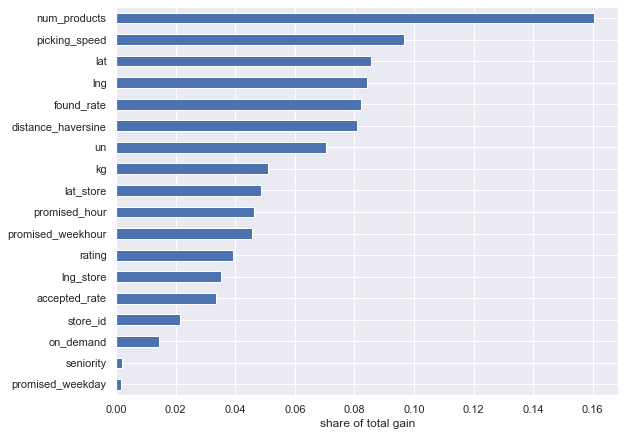

In [23]:
importances = pd.Series(model.booster_.feature_importance(importance_type='gain'), index=FEATURES)
(importances / importances.sum()).sort_values().plot(kind='barh', figsize=(9, 7))
plt.xlabel('share of total gain'); plt.show()

### Error analysis
Where does the model go wrong? We look at absolute errors by order size and by order type.

In [24]:
errors = X_test.assign(y=y_test, pred=test_pred, abs_err=np.abs(y_test - test_pred))
errors['size_bucket'] = pd.qcut(errors['num_products'], 5)

print(errors.groupby('size_bucket', observed=True).agg(
    n=('abs_err', 'size'), mae=('abs_err', 'mean'), mean_target=('y', 'mean')).round(1))
print()
print(errors.groupby('on_demand').agg(n=('abs_err', 'size'), mae=('abs_err', 'mean'), mean_target=('y', 'mean')).round(1))
print()
print('median signed error (y - pred): {:.1f} min'.format((errors['y'] - errors['pred']).median()))

                 n   mae  mean_target
size_bucket                          
(0.999, 6.0]   350  15.0         57.7
(6.0, 13.0]    308  15.0         67.1
(13.0, 21.0]   329  15.4         79.2
(21.0, 32.0]   301  16.6         92.0
(32.0, 145.0]  307  16.8        112.7

             n   mae  mean_target
on_demand                        
0          869  16.9         88.8
1          731  14.2         71.5

median signed error (y - pred): -1.8 min


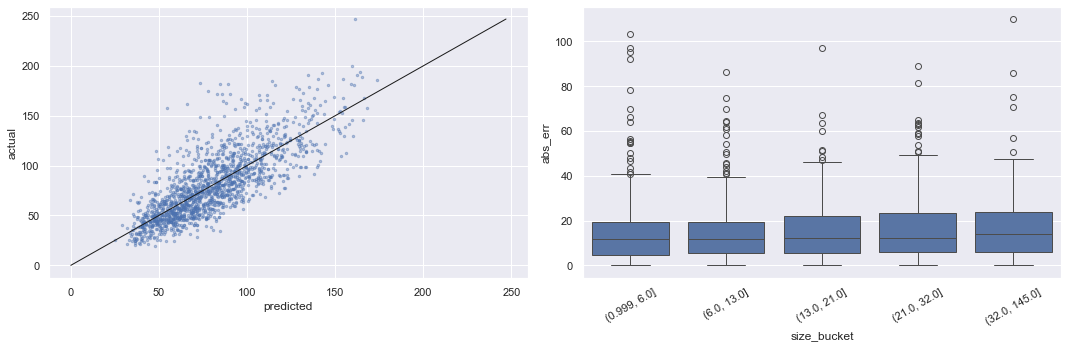

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(errors['pred'], errors['y'], s=6, alpha=0.4)
lim = [0, errors[['y', 'pred']].max().max()]
axes[0].plot(lim, lim, color='k', lw=1); axes[0].set_xlabel('predicted'); axes[0].set_ylabel('actual')
sns.boxplot(x='size_bucket', y='abs_err', data=errors, ax=axes[1]); axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

The absolute error grows only slightly with order size (≈ 15 → 17 min), while the target nearly doubles, so the
*relative* error is largest for small orders (≈ 26% vs ≈ 15% for the largest baskets). Small orders are dominated
by fixed overheads (travel, waiting, checkout) that the features capture poorly. On-demand orders are predicted better
than scheduled ones. The model slightly over-predicts (median signed error ≈ −2 min).
The large positive residuals (orders that took much longer than predicted) come from factors we can't see in the data,
such as out-of-stock substitutions, queues and traffic.

### Is shuffled CV the right validation?

Shuffled K-fold assumes the rows we hold out look like the rows we will predict. **For this test they do**: the
unlabeled orders cover the same time window as the labeled ones, about 20% of the orders in every hour are
unlabeled, and nearly all their shoppers and branches also appear in the labeled data. Shuffled CV therefore
matches the submission setting.

In production, though, the model would predict *future* orders, possibly for new shoppers or branches. To see how
optimistic shuffled CV is for that case, we re-evaluate the final model (same parameters, all labeled data)
with stricter splits:
- **grouped by shopper / branch:** no shopper (or branch) appears in both train and test;
- **time-ordered (forward chaining):** sort by promised time, train on the first k/6 of orders, test on the next 1/6;
- **Friday → Saturday:** train on one day, test on the next.

In [26]:
from sklearn.model_selection import GroupKFold

unlabeled = df['total_minutes'].isna()
print('unlabeled share per local hour: {:.2f}–{:.2f}'.format(
    *df.loc[df['promised_hour'].between(10, 22)].groupby('promised_hour')['total_minutes']
       .apply(lambda s: s.isna().mean()).agg(['min', 'max'])))
print('unlabeled orders whose shopper is in the labeled data: {:.1%}'.format(
    df.loc[unlabeled, 'shopper_id'].isin(df.loc[~unlabeled, 'shopper_id']).mean()))
print('unlabeled orders whose branch is in the labeled data:  {:.1%}'.format(
    df.loc[unlabeled, 'store_branch_id'].isin(df.loc[~unlabeled, 'store_branch_id']).mean()))

lab = labeled.reset_index(drop=True)
X_all, y_all = lab[FEATURES], lab['total_minutes']
promised = lab['order_id'].map(pd.Series(promised_local.values, index=orders['order_id']))
by_time = np.argsort(promised.values)
n = len(lab)
friday = (promised.dt.weekday == 4).values

schemes = {
    'shuffled 5-fold (used above)': KFold(5, shuffle=True, random_state=RANDOM_STATE).split(X_all),
    'grouped by shopper': GroupKFold(5).split(X_all, y_all, lab['shopper_id']),
    'grouped by store branch': GroupKFold(5).split(X_all, y_all, lab['store_branch_id']),
    'time-ordered (forward chaining)': [(by_time[:n * k // 6], by_time[n * k // 6:n * (k + 1) // 6]) for k in range(2, 6)],
    'train Friday -> test Saturday': [(np.where(friday)[0], np.where(~friday)[0])],
}
rows = []
for name, splits in schemes.items():
    errs = [mean_absolute_error(y_all.iloc[te], lgbm(**final_params).fit(X_all.iloc[tr], y_all.iloc[tr]).predict(X_all.iloc[te]))
            for tr, te in splits]
    rows.append((name, np.mean(errs), np.std(errs)))
pd.DataFrame(rows, columns=['validation', 'mae', 'std']).round(2)

unlabeled share per local hour: 0.19–0.23
unlabeled orders whose shopper is in the labeled data: 92.2%
unlabeled orders whose branch is in the labeled data:  97.9%


,validation,mae,std
0,shuffled 5-fold (used above),16.07,0.49
1,grouped by shopper,16.20,0.50
2,grouped by store branch,17.26,2.00
3,time-ordered (forward chaining),18.41,0.67
4,train Friday -> test Saturday,19.70,0.00


- **Shoppers:** grouping barely changes the error, so the model is not memorizing individual shoppers through their
  per-shopper statistics.
- **Branches:** about 1 minute worse, with high variance. Part of the location gain comes from recognizing specific
  branches, so new stores will be predicted less accurately.
- **Time:** 2–3 minutes worse. Part of that is because the earlier folds train on less data, and part is a real shift
  (Friday afternoon vs all of Saturday, and the model can't learn a Saturday effect from Friday-only data).
  Two days is too short to separate the two.

**Conclusion:** shuffled CV is the right tool for *this* test, because the submission orders are a random sample of
the same window. For orders on future days, **≈ 18.4–19.7 min MAE** is the more realistic expectation.

## Submission file
With the model and parameters chosen, we **refit on all 8,000 labeled orders**, because the hold-out set has done its job
and more data helps. Then we predict every unlabeled order. The asserts check that the file covers exactly the 2,000
unlabeled orders.

In [27]:
final_model = lgbm(**final_params).fit(X, y)
predicted = final_model.predict(submission_df[FEATURES])

submission = pd.DataFrame({'order_id': submission_df['order_id'], 'total_minutes': predicted})
expected_ids = set(orders.loc[orders['total_minutes'].isna(), 'order_id'])
assert len(submission) == len(expected_ids) and set(submission['order_id']) == expected_ids
assert submission['total_minutes'].notna().all() and (submission['total_minutes'] > 0).all()

submission.to_csv('data/submission.csv', index=False)
print(submission.shape)
submission['total_minutes'].describe().round(1)

(2000, 2)


count    2000.0
mean       79.1
std        25.9
min        24.2
25%        59.6
50%        75.3
75%        94.5
max       187.5
Name: total_minutes, dtype: float64

## Conclusions and next steps
See the *Approach, results and limitations* section of the README for the summary. In short:
- The final LightGBM model (L1 loss) cuts the mean-baseline MAE by roughly 40%. The ablation above shows what each change contributed.
- The biggest wins came from **matching the loss to the metric** and from **location information** (store chain and coordinates).
- Hyperparameter tuning matters much less than features.

Next steps with more data: historical per-shopper and per-branch timings (target encoding gave no gain here, with only about 3 orders
per shopper), real routing distance or travel time instead of haversine, product or category-level features (for example
weighed products and hard-to-find items), and real-time load (concurrent orders per branch or shopper).